In [2]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from shapely.geometry import Point, LineString, Polygon, MultiPoint, mapping
import numpy as np
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
import plotly.express as px
import json

In [6]:
### NOW TO GET A POLYGON LAYER (INDIA) 
india_districts = gpd.read_file("gadm41_IND_shp/gadm41_IND_2.shp") 
india_districts

,GID_2,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2,geometry
0,IND.1.1_1,IND,India,IND.1_1,Andaman and Nicobar,NA,Nicobar Islands,NA,NA,District,District,NA,IN.AN.NI,"MULTIPOLYGON (((93.78988 6.85201, 93.79015 6.8..."
1,IND.1.2_1,IND,India,IND.1_1,Andaman and Nicobar,NA,North and Middle Andaman,NA,NA,District,District,NA,IN.AN.NM,"MULTIPOLYGON (((92.84441 12.14969, 92.84466 12..."
2,IND.1.3_1,IND,India,IND.1_1,Andaman and Nicobar,NA,South Andaman,NA,NA,District,District,NA,IN.AN.SA,"MULTIPOLYGON (((92.52111 10.89694, 92.52306 10..."
3,IND.2.1_1,IND,India,IND.2_1,Andhra Pradesh,NA,Anantapur,"Anantpur, Ananthapur",NA,District,District,NA,IN.AD.AN,"POLYGON ((77.846 13.92832, 77.83012 13.92715, ..."
4,IND.2.2_1,IND,India,IND.2_1,Andhra Pradesh,NA,Chittoor,Chitoor|Chittor,NA,District,District,NA,IN.AD.CH,"POLYGON ((78.54555 12.74391, 78.55031 12.73876..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,IND.36.16_1,IND,India,IND.36_1,West Bengal,NA,Pashchim Medinipur,Paschim Medinipur,NA,District,District,NA,IN.WB.WM,"POLYGON ((86.72535 22.2135, 86.73376 22.21122,..."
672,IND.36.17_1,IND,India,IND.36_1,West Bengal,NA,Purba Medinipur,Purba Medinipur,NA,District,District,NA,IN.WB.EM,"MULTIPOLYGON (((87.48176 21.60946, 87.48171 21..."
673,IND.36.18_1,IND,India,IND.36_1,West Bengal,NA,Puruliya,NA,NA,District,District,NA,IN.WB.PU,"POLYGON ((85.87758 23.47586, 85.89125 23.47598..."
674,IND.36.19_1,IND,India,IND.36_1,West Bengal,NA,South 24 Parganas,NA,NA,District,District,NA,IN.WB.PS,"MULTIPOLYGON (((88.02139 21.57111, 88.02111 21..."


In [9]:
## getting kerala's districts
kerala_districts = india_districts[india_districts["NAME_1"] == "Kerala"].copy()
kerala_districts

,GID_2,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2,geometry
281,IND.17.1_1,IND,India,IND.17_1,Kerala,NA,Alappuzha,Alleppey,NA,District,District,NA,IN.KL.AL,"MULTIPOLYGON (((76.62915 9.20714, 76.62963 9.2..."
282,IND.17.2_1,IND,India,IND.17_1,Kerala,NA,Ernakulam,NA,NA,District,District,NA,IN.KL.ER,"MULTIPOLYGON (((76.37708 9.84042, 76.37708 9.8..."
283,IND.17.3_1,IND,India,IND.17_1,Kerala,NA,Idukki,Idikki,NA,District,District,NA,IN.KL.ID,"POLYGON ((77.19907 10.07066, 77.20444 10.06849..."
284,IND.17.4_1,IND,India,IND.17_1,Kerala,NA,Kannur,Cannanore,NA,District,District,NA,IN.KL.KN,"MULTIPOLYGON (((75.74294 12.07178, 75.74759 12..."
285,IND.17.5_1,IND,India,IND.17_1,Kerala,NA,Kasaragod,NA,NA,District,District,NA,IN.KL.KS,"MULTIPOLYGON (((75.12681 12.20403, 75.12653 12..."
286,IND.17.6_1,IND,India,IND.17_1,Kerala,NA,Kollam,Quilon,NA,District,District,NA,IN.KL.KL,"POLYGON ((76.70185 9.07693, 76.70963 9.07432, ..."
287,IND.17.7_1,IND,India,IND.17_1,Kerala,NA,Kottayam,NA,NA,District,District,NA,IN.KL.KT,"MULTIPOLYGON (((76.49538 9.40856, 76.4969 9.41..."
288,IND.17.8_1,IND,India,IND.17_1,Kerala,NA,Kozhikode,Calicut,NA,District,District,NA,IN.KL.KZ,"MULTIPOLYGON (((75.83847 11.13403, 75.83847 11..."
289,IND.17.9_1,IND,India,IND.17_1,Kerala,NA,Malappuram,NA,NA,District,District,NA,IN.KL.MA,"POLYGON ((76.02329 10.80981, 76.02842 10.80651..."
290,IND.17.10_1,IND,India,IND.17_1,Kerala,NA,Palakkad,Palghat,NA,District,District,NA,IN.KL.PL,"POLYGON ((76.67487 10.9064, 76.6846 10.90243, ..."


In [10]:
tamil_dist_kerala_plsi_df = pd.read_csv("tamil_perc_district_mapping_2001_plsi.csv")
tamil_dist_kerala_plsi_df

,district,language,speakers,district_population
0,Kasaragod,Tamil,5065,NaN
1,Kannur,Tamil,9560,NaN
2,Wayanad,Tamil,10172,NaN
3,Kozhikode,Tamil,13298,NaN
4,Malappuram,Tamil,13264,NaN
5,Palakkad,Tamil,160991,NaN
6,Thrissur,Tamil,18772,NaN
7,Ernakulam,Tamil,39013,NaN
8,Idukki,Tamil,221734,NaN
9,Kottayam,Tamil,13940,NaN


In [12]:
merged_tamil_kerala_plsi_df = kerala_districts.merge(tamil_dist_kerala_plsi_df, left_on="NAME_2", right_on="district")
merged_tamil_kerala_plsi_df.head()

,GID_2,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2,geometry,district,language,speakers,district_population
0,IND.17.1_1,IND,India,IND.17_1,Kerala,NA,Alappuzha,Alleppey,NA,District,District,NA,IN.KL.AL,"MULTIPOLYGON (((76.62915 9.20714, 76.62963 9.2...",Alappuzha,Tamil,7202,NaN
1,IND.17.2_1,IND,India,IND.17_1,Kerala,NA,Ernakulam,NA,NA,District,District,NA,IN.KL.ER,"MULTIPOLYGON (((76.37708 9.84042, 76.37708 9.8...",Ernakulam,Tamil,39013,NaN
2,IND.17.3_1,IND,India,IND.17_1,Kerala,NA,Idukki,Idikki,NA,District,District,NA,IN.KL.ID,"POLYGON ((77.19907 10.07066, 77.20444 10.06849...",Idukki,Tamil,221734,NaN
3,IND.17.4_1,IND,India,IND.17_1,Kerala,NA,Kannur,Cannanore,NA,District,District,NA,IN.KL.KN,"MULTIPOLYGON (((75.74294 12.07178, 75.74759 12...",Kannur,Tamil,9560,NaN
4,IND.17.5_1,IND,India,IND.17_1,Kerala,NA,Kasaragod,NA,NA,District,District,NA,IN.KL.KS,"MULTIPOLYGON (((75.12681 12.20403, 75.12653 12...",Kasaragod,Tamil,5065,NaN


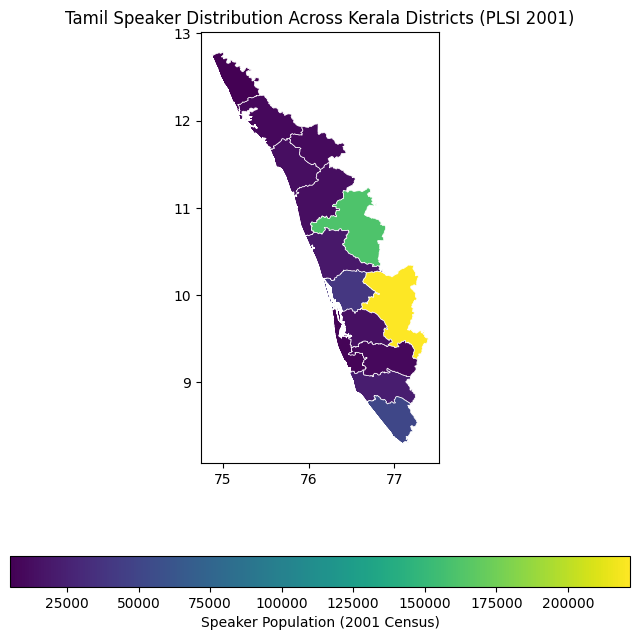

In [13]:
fig, ax = plt.subplots(figsize=(8,8))

merged_tamil_kerala_plsi_df.plot(
    ax=ax,
    column="speakers",
    legend=True, 
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={"label": "Speaker Population (2001 Census)", "orientation": "horizontal"}

);

ax.set_title(
    "Tamil Speaker Distribution Across Kerala Districts (PLSI 2001)", fontsize=12
);

In [15]:
c_16_district_kerala_df = pd.read_csv("dravidian_languages_kerala_district-level.csv")
c_16_district_kerala_df

,State,District,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
0,Kerala,Kasaragod,Malayalam,480405,231392,249013,299719,145061,154658,180686,86331,94355
1,Kerala,Kannur,Malayalam,2494784,1161882,1332902,873059,418682,454377,1621725,743200,878525
2,Kerala,Wayanad,Malayalam,767404,376663,390741,739778,363230,376548,27626,13433,14193
3,Kerala,Kozhikode,Malayalam,3056849,1451749,1605100,1008616,481008,527608,2048233,970741,1077492
4,Kerala,Malappuram,Malayalam,4090843,1945340,2145503,2286148,1088796,1197352,1804695,856544,948151
5,Kerala,Palakkad,Malayalam,2633048,1269938,1363110,2002699,965746,1036953,630349,304192,326157
6,Kerala,Thrissur,Malayalam,3086914,1460195,1626719,1016273,483193,533080,2070641,977002,1093639
7,Kerala,Ernakulam,Malayalam,3174165,1556660,1617505,1037946,511333,526613,2136219,1045327,1090892
8,Kerala,Idukki,Malayalam,907589,451174,456415,856126,426011,430115,51463,25163,26300
9,Kerala,Kottayam,Malayalam,1952383,954198,998185,1399082,685716,713366,553301,268482,284819


In [19]:
# taking all the malayalam rows 
c_16_kerala_tamil_df = c_16_district_kerala_df[c_16_district_kerala_df["Mother tongue"] == "Tamil"]

# merging 
merged_kerala_tamil_c16 = kerala_districts.merge(
    c_16_kerala_tamil_df[["District", "Total_P", "Rural_P", "Urban_P"]],
    left_on = "NAME_2",
    right_on = "District", 
    how = "left", 
    validate="one_to_one"
)

In [20]:
merged_kerala_tamil_c16

,GID_2,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2,geometry,District,Total_P,Rural_P,Urban_P
0,IND.17.1_1,IND,India,IND.17_1,Kerala,NA,Alappuzha,Alleppey,NA,District,District,NA,IN.KL.AL,"MULTIPOLYGON (((76.62915 9.20714, 76.62963 9.2...",Alappuzha,5372,1414,3958
1,IND.17.2_1,IND,India,IND.17_1,Kerala,NA,Ernakulam,NA,NA,District,District,NA,IN.KL.ER,"MULTIPOLYGON (((76.37708 9.84042, 76.37708 9.8...",Ernakulam,30965,2598,28367
2,IND.17.3_1,IND,India,IND.17_1,Kerala,NA,Idukki,Idikki,NA,District,District,NA,IN.KL.ID,"POLYGON ((77.19907 10.07066, 77.20444 10.06849...",Idukki,193841,193597,244
3,IND.17.4_1,IND,India,IND.17_1,Kerala,NA,Kannur,Cannanore,NA,District,District,NA,IN.KL.KN,"MULTIPOLYGON (((75.74294 12.07178, 75.74759 12...",Kannur,8140,1632,6508
4,IND.17.5_1,IND,India,IND.17_1,Kerala,NA,Kasaragod,NA,NA,District,District,NA,IN.KL.KS,"MULTIPOLYGON (((75.12681 12.20403, 75.12653 12...",Kasaragod,4314,1411,2903
5,IND.17.6_1,IND,India,IND.17_1,Kerala,NA,Kollam,Quilon,NA,District,District,NA,IN.KL.KL,"POLYGON ((76.70185 9.07693, 76.70963 9.07432, ...",Kollam,16546,9301,7245
6,IND.17.7_1,IND,India,IND.17_1,Kerala,NA,Kottayam,NA,NA,District,District,NA,IN.KL.KT,"MULTIPOLYGON (((76.49538 9.40856, 76.4969 9.41...",Kottayam,12537,4861,7676
7,IND.17.8_1,IND,India,IND.17_1,Kerala,NA,Kozhikode,Calicut,NA,District,District,NA,IN.KL.KZ,"MULTIPOLYGON (((75.83847 11.13403, 75.83847 11...",Kozhikode,10506,1611,8895
8,IND.17.9_1,IND,India,IND.17_1,Kerala,NA,Malappuram,NA,NA,District,District,NA,IN.KL.MA,"POLYGON ((76.02329 10.80981, 76.02842 10.80651...",Malappuram,10565,4310,6255
9,IND.17.10_1,IND,India,IND.17_1,Kerala,NA,Palakkad,Palghat,NA,District,District,NA,IN.KL.PL,"POLYGON ((76.67487 10.9064, 76.6846 10.90243, ...",Palakkad,135498,98629,36869


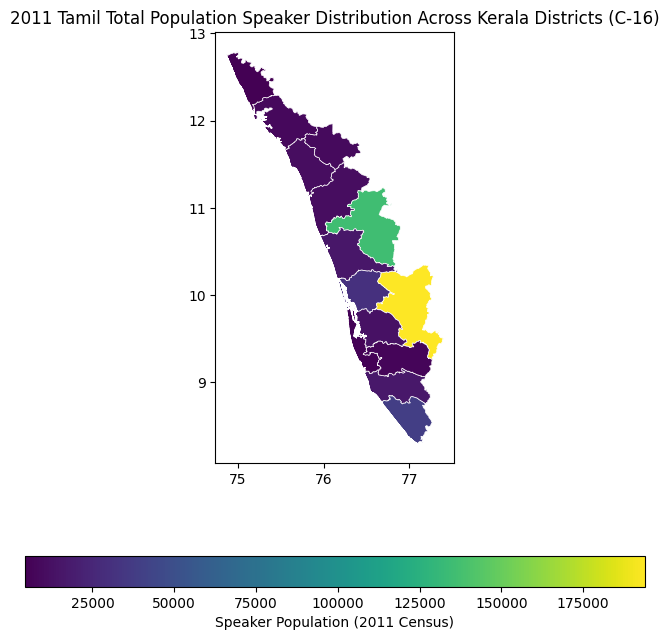

In [25]:
## making a full district map 

fig, ax = plt.subplots(figsize=(8,8))

merged_kerala_tamil_c16.plot(
    ax=ax,
    column="Total_P",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}

);

ax.set_title(
    "2011 Tamil Total Population Speaker Distribution Across Kerala Districts (C-16)", fontsize=12
);

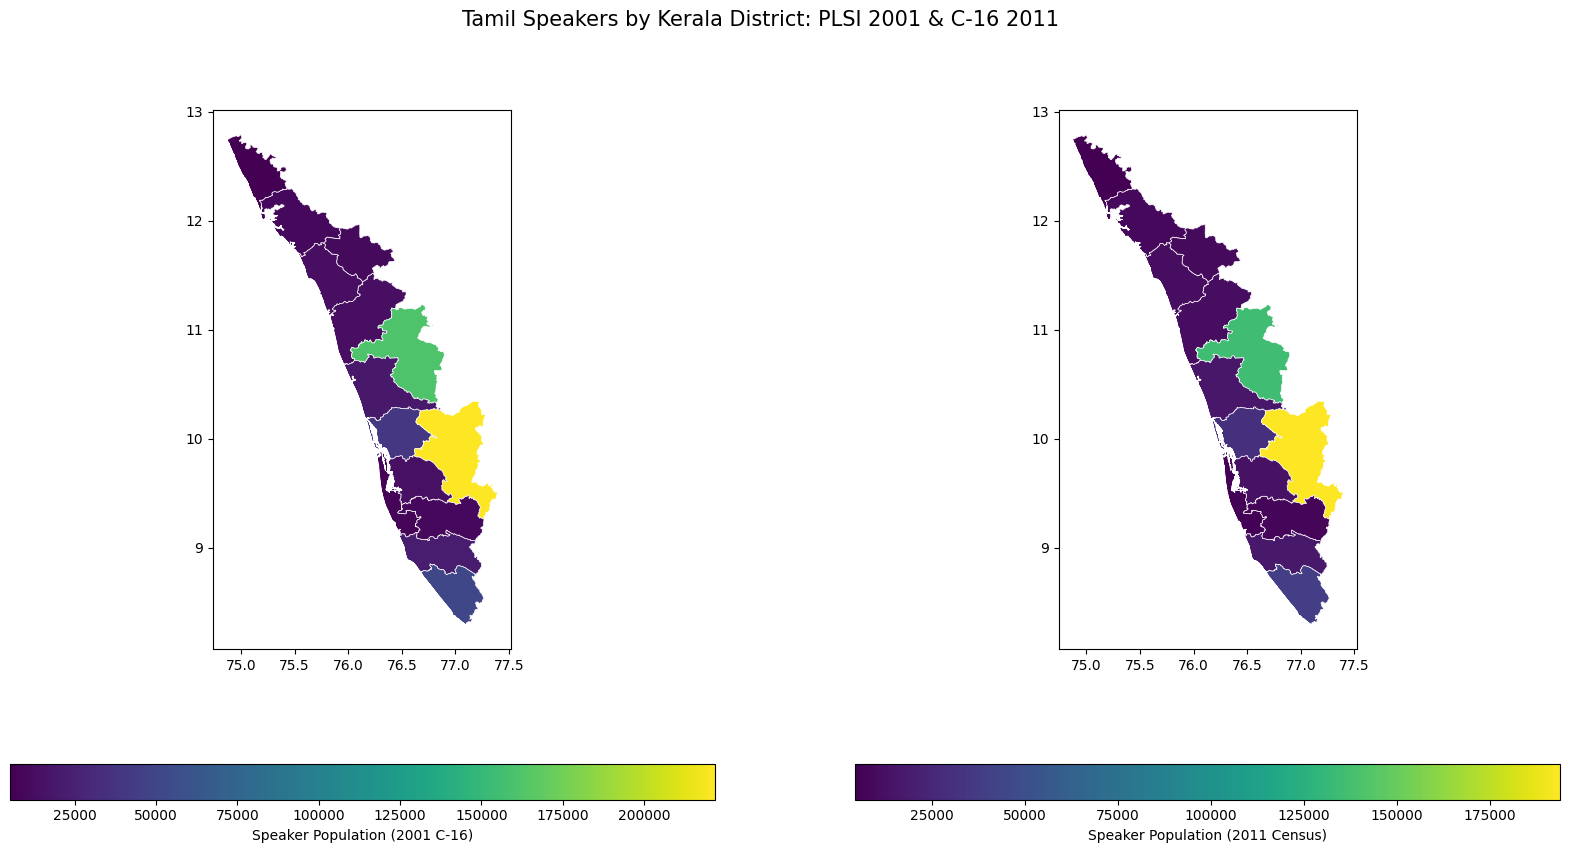

In [61]:
## making a multiples map layout showing each of these side by side
fig, ax = plt.subplots(1, 2, figsize=(20,10))
fig.suptitle("Tamil Speakers by Kerala District: PLSI 2001 & C-16 2011", fontsize=15);

## using map plotting calls 


merged_tamil_kerala_plsi_df.plot(
    ax=ax[0],
    column="speakers",
    legend=True, 
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={"label": "Speaker Population (2001 C-16)", "orientation": "horizontal"}
)

merged_kerala_tamil_c16.plot(
    ax=ax[1],
    column="Total_P",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);

In [33]:
merged_kerala_tamil_c16

merged_tamil_kerala_plsi_df[["NAME_2", "speakers"]]

tamil_in_kerala_comparison = merged_kerala_tamil_c16.merge(
    merged_tamil_kerala_plsi_df[["NAME_2", "speakers"]],
    on = "NAME_2",
    how = "left", 
    validate="one_to_one"
)

In [36]:
tamil_in_kerala_comparison

,GID_2,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2,geometry,District,Total_P,Rural_P,Urban_P,speakers
0,IND.17.1_1,IND,India,IND.17_1,Kerala,NA,Alappuzha,Alleppey,NA,District,District,NA,IN.KL.AL,"MULTIPOLYGON (((76.62915 9.20714, 76.62963 9.2...",Alappuzha,5372,1414,3958,7202
1,IND.17.2_1,IND,India,IND.17_1,Kerala,NA,Ernakulam,NA,NA,District,District,NA,IN.KL.ER,"MULTIPOLYGON (((76.37708 9.84042, 76.37708 9.8...",Ernakulam,30965,2598,28367,39013
2,IND.17.3_1,IND,India,IND.17_1,Kerala,NA,Idukki,Idikki,NA,District,District,NA,IN.KL.ID,"POLYGON ((77.19907 10.07066, 77.20444 10.06849...",Idukki,193841,193597,244,221734
3,IND.17.4_1,IND,India,IND.17_1,Kerala,NA,Kannur,Cannanore,NA,District,District,NA,IN.KL.KN,"MULTIPOLYGON (((75.74294 12.07178, 75.74759 12...",Kannur,8140,1632,6508,9560
4,IND.17.5_1,IND,India,IND.17_1,Kerala,NA,Kasaragod,NA,NA,District,District,NA,IN.KL.KS,"MULTIPOLYGON (((75.12681 12.20403, 75.12653 12...",Kasaragod,4314,1411,2903,5065
5,IND.17.6_1,IND,India,IND.17_1,Kerala,NA,Kollam,Quilon,NA,District,District,NA,IN.KL.KL,"POLYGON ((76.70185 9.07693, 76.70963 9.07432, ...",Kollam,16546,9301,7245,22837
6,IND.17.7_1,IND,India,IND.17_1,Kerala,NA,Kottayam,NA,NA,District,District,NA,IN.KL.KT,"MULTIPOLYGON (((76.49538 9.40856, 76.4969 9.41...",Kottayam,12537,4861,7676,13940
7,IND.17.8_1,IND,India,IND.17_1,Kerala,NA,Kozhikode,Calicut,NA,District,District,NA,IN.KL.KZ,"MULTIPOLYGON (((75.83847 11.13403, 75.83847 11...",Kozhikode,10506,1611,8895,13298
8,IND.17.9_1,IND,India,IND.17_1,Kerala,NA,Malappuram,NA,NA,District,District,NA,IN.KL.MA,"POLYGON ((76.02329 10.80981, 76.02842 10.80651...",Malappuram,10565,4310,6255,13264
9,IND.17.10_1,IND,India,IND.17_1,Kerala,NA,Palakkad,Palghat,NA,District,District,NA,IN.KL.PL,"POLYGON ((76.67487 10.9064, 76.6846 10.90243, ...",Palakkad,135498,98629,36869,160991


In [40]:
## listing the districts along with speaker populations side by side from both sources
tamil_in_kerala_comparison[["NAME_2", "Total_P", "speakers"]]

,NAME_2,Total_P,speakers
0,Alappuzha,5372,7202
1,Ernakulam,30965,39013
2,Idukki,193841,221734
3,Kannur,8140,9560
4,Kasaragod,4314,5065
5,Kollam,16546,22837
6,Kottayam,12537,13940
7,Kozhikode,10506,13298
8,Malappuram,10565,13264
9,Palakkad,135498,160991


In [43]:
## adding new column displaying the difference from 2011 (Total_P) and 2001 (speakers) 
tamil_in_kerala_comparison["Total_P - speakers"] = tamil_in_kerala_comparison["Total_P"] - tamil_in_kerala_comparison["speakers"]
tamil_in_kerala_comparison[["NAME_2", "Total_P", "speakers", "Total_P - speakers"]]

,NAME_2,Total_P,speakers,Total_P - speakers
0,Alappuzha,5372,7202,-1830
1,Ernakulam,30965,39013,-8048
2,Idukki,193841,221734,-27893
3,Kannur,8140,9560,-1420
4,Kasaragod,4314,5065,-751
5,Kollam,16546,22837,-6291
6,Kottayam,12537,13940,-1403
7,Kozhikode,10506,13298,-2792
8,Malappuram,10565,13264,-2699
9,Palakkad,135498,160991,-25493


#### The change was shown to be negative. Possible reduction?

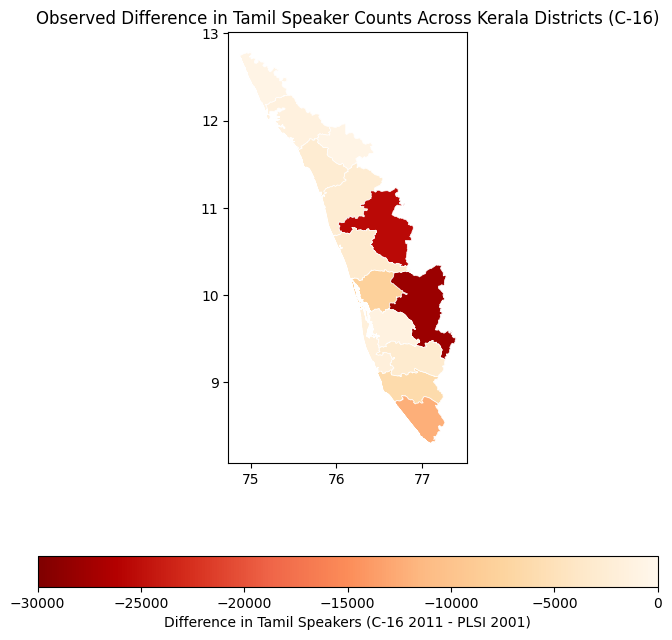

In [58]:
# visualizing the change
fig, ax = plt.subplots(figsize=(8,8))

tamil_in_kerala_comparison.plot(
    ax=ax,
    column="Total_P - speakers",
    cmap="OrRd_r",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={"label": "Difference in Tamil Speakers (C-16 2011 - PLSI 2001)", "orientation": "horizontal"},
    vmin=-30000,
    vmax=0
);

ax.set_title(
    "Observed Difference in Tamil Speaker Counts Across Kerala Districts (C-16)", fontsize=12
); 

## Percentage Version

In [62]:
tamil_in_kerala_comparison["Percentage Difference"] = tamil_in_kerala_comparison["Total_P - speakers"]/tamil_in_kerala_comparison["speakers"] * 100

In [63]:
tamil_in_kerala_comparison[["NAME_2", "Total_P", "speakers", "Total_P - speakers", "Percentage Difference"]]

,NAME_2,Total_P,speakers,Total_P - speakers,Percentage Difference
0,Alappuzha,5372,7202,-1830,-25.409608
1,Ernakulam,30965,39013,-8048,-20.629021
2,Idukki,193841,221734,-27893,-12.579487
3,Kannur,8140,9560,-1420,-14.853556
4,Kasaragod,4314,5065,-751,-14.827246
5,Kollam,16546,22837,-6291,-27.547401
6,Kottayam,12537,13940,-1403,-10.064562
7,Kozhikode,10506,13298,-2792,-20.995638
8,Malappuram,10565,13264,-2699,-20.348311
9,Palakkad,135498,160991,-25493,-15.835047


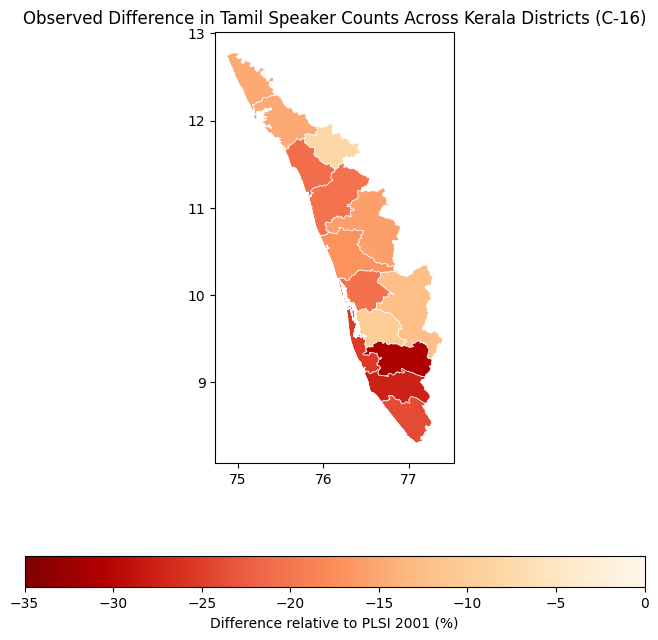

In [66]:
# visualizing the change
fig, ax = plt.subplots(figsize=(8,8))

tamil_in_kerala_comparison.plot(
    ax=ax,
    column="Percentage Difference",
    cmap="OrRd_r",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={"label": "Difference relative to PLSI 2001 (%)", "orientation": "horizontal"},
    vmin=-35,
    vmax=0
);

ax.set_title(
    "Observed Difference in Tamil Speaker Counts Across Kerala Districts (C-16)", fontsize=12
); 